# 05 — Explicabilidade: por que o modelo decidiu assim

> Explica as decisões do modelo publicado — o `models/model.joblib` que `make train` publica e
> a API serve —, na partição de **teste**, com a regra de decisão que ele usa (recusa a partir
> de 0,5). Duas perguntas: **o que pesa no modelo como um todo** e **por que um pedido
> específico foi aprovado ou recusado**. O modelo não é alterado.
>
> Para reexecutar: `make train` (para existir o modelo publicado), `poetry install --with
> notebooks` e depois `make explicabilidade`.

**A ferramenta: valores SHAP.** O modelo dá a cada pedido uma nota de risco. Os valores SHAP
dividem essa nota entre as variáveis, como uma conta dividida entre quem consumiu: cada
variável recebe a sua parte — positiva se empurrou o risco para cima, negativa se empurrou
para baixo —, e as partes somam **exatamente** a nota final. O ponto de partida, comum a todos
os pedidos, é a nota média.

O XGBoost calcula esses valores de forma exata para árvores (*TreeSHAP*), sem biblioteca
adicional.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from IPython.display import display

from credito.config import get_settings
from credito.data.arff import ler_arff
from credito.data.prepare import limpar, separar
from credito.model.evaluate import FAIXAS_ETARIAS
from credito.model.train import carregar_modelo
from credito.schema import ALVO, FEATURES

warnings.filterwarnings("ignore", category=UserWarning)
pd.options.display.float_format = "{:,.4f}".format

AZUL, LARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, GRADE, FUNDO = "#0b0b0b", "#52514e", "#e5e4df", "#fcfcfb"
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "figure.facecolor": FUNDO,
        "axes.facecolor": FUNDO,
        "axes.edgecolor": TINTA_2,
        "axes.labelcolor": TINTA_2,
        "axes.titlecolor": TINTA,
        "axes.titlesize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.color": GRADE,
        "grid.linewidth": 0.8,
        "xtick.color": TINTA_2,
        "ytick.color": TINTA_2,
        "font.size": 10,
        "legend.frameon": False,
    }
)

settings = get_settings()
X = list(FEATURES)
LIMIAR = 0.5
NOMES = {
    "RevolvingUtilizationOfUnsecuredLines": "uso_rotativo",
    "age": "idade",
    "NumberOfTime30-59DaysPastDueNotWorse": "atraso_30_59",
    "DebtRatio": "razao_divida",
    "MonthlyIncome": "renda_mensal",
    "NumberOfOpenCreditLinesAndLoans": "linhas_abertas",
    "NumberOfTimes90DaysLate": "atraso_90",
    "NumberRealEstateLoansOrLines": "imobiliario",
    "NumberOfTime60-89DaysPastDueNotWorse": "atraso_60_89",
    "NumberOfDependents": "dependentes",
}

referencia, _ = limpar(ler_arff(settings.dataset_path))
teste = separar(
    referencia,
    test_size=settings.test_size,
    validation_size=settings.validation_size,
    seed=settings.random_seed,
)["teste"]
modelo, metadados = carregar_modelo(settings.model_path)
classificador = modelo[-1]
print(f"modelo publicado: {metadados.get('candidato')} | teste: {len(teste):,} pedidos")

y = teste[ALVO].to_numpy()
p = modelo.predict_proba(teste[X])[:, 1]
recusa = p >= LIMIAR
faixa = np.full(len(teste), "", dtype=object)
for nome, (minimo, maximo) in FAIXAS_ETARIAS.items():
    faixa[teste["age"].between(minimo, maximo).to_numpy()] = nome

modelo publicado: xgboost | teste: 23,584 pedidos


## 1. Conferindo a ferramenta

Antes de usar as explicações, duas verificações:

1. **A soma fecha.** Ponto de partida mais as dez contribuições tem de dar exatamente a nota
   do modelo, para todos os pedidos.
2. **A explicação vale para a probabilidade corrigida.** O modelo publicado foi treinado com
   peso de classe $w$, que infla as probabilidades (`03_baseline.ipynb`, seção 4). A nota em
   que o SHAP trabalha é o *log-odds*, $\log\frac{p}{1-p}$. Nessa escala, a correção de prior
   $p' = \frac{p}{p + w(1-p)}$ é só **subtrair a constante $\log w$** de todas as notas. Logo,
   as contribuições de cada variável são as mesmas para o modelo inflado e para o corrigido —
   só o ponto de partida muda.

In [2]:
matriz = xgb.DMatrix(teste[X])
contribuicoes = classificador.get_booster().predict(matriz, pred_contribs=True)
shap = pd.DataFrame(contribuicoes[:, :-1], columns=[NOMES[c] for c in X], index=teste.index)
partida = float(contribuicoes[0, -1])
nota = classificador.get_booster().predict(matriz, output_margin=True)

peso = classificador.get_params()["scale_pos_weight"]
p_corrigida = p / (p + peso * (1 - p))
log_odds = np.log(p / (1 - p))
log_odds_corrigido = np.log(p_corrigida / (1 - p_corrigida))

erro_da_soma = np.abs(partida + shap.sum(axis=1) - nota).max()
deslocamento = log_odds - log_odds_corrigido
partida_corrigida = partida - np.log(peso)
print(f"maior erro da soma (partida + contribuições - nota): {erro_da_soma:.2e}")
print(
    f"log-odds inflado menos corrigido: de {deslocamento.min():.6f} a {deslocamento.max():.6f}; "
    f"log(w) = {np.log(peso):.6f}"
)
print(
    f"ponto de partida: {partida:.4f} no modelo inflado, {partida_corrigida:.4f} no corrigido "
    f"(probabilidade {1 / (1 + np.exp(-partida_corrigida)):.2%})"
)
print(
    f"o corte de 0,5 do modelo inflado equivale a {1 / (1 + peso):.2%} de probabilidade corrigida; "
    f"inadimplência do teste: {y.mean():.2%}"
)

maior erro da soma (partida + contribuições - nota): 7.15e-06
log-odds inflado menos corrigido: de 2.595500 a 2.595501; log(w) = 2.595501
ponto de partida: 0.1026 no modelo inflado, -2.4929 no corrigido (probabilidade 7.64%)
o corte de 0,5 do modelo inflado equivale a 6.94% de probabilidade corrigida; inadimplência do teste: 6.94%


- **A soma fecha:** o maior erro, em 23.584 pedidos, é de 7 milionésimos — arredondamento
  numérico.
- **A explicação vale para a probabilidade corrigida:** a diferença entre o log-odds inflado
  e o corrigido é a mesma constante, 2,5955 = log(w), para todos os pedidos. As contribuições
  de cada variável, portanto, valem igualmente para os dois.

E sai daqui uma tradução útil do corte de decisão. **O corte de 0,5 do modelo publicado
equivale a 6,94% de probabilidade real — exatamente a inadimplência média da base.** Não é
coincidência: o peso de classe é a razão entre adimplentes e inadimplentes do treino. Em
linguagem comum, a regra do modelo é: **recusa quem tem risco estimado acima da média.**

## 2. O que pesa no modelo como um todo

A importância global de uma variável é o **tamanho médio da sua contribuição**, sem sinal,
somado em todos os pedidos do teste: quanto, em média, ela move a nota de alguém.

,contribuição média absoluta (log-odds),% do total
uso_rotativo,0.9184,32.5183
atraso_30_59,0.3789,13.4147
atraso_90,0.3227,11.4247
idade,0.2499,8.8479
razao_divida,0.2212,7.8310
renda_mensal,0.2167,7.6740
atraso_60_89,0.1916,6.7827
linhas_abertas,0.1726,6.1102
imobiliario,0.1047,3.7072
dependentes,0.0477,1.6893


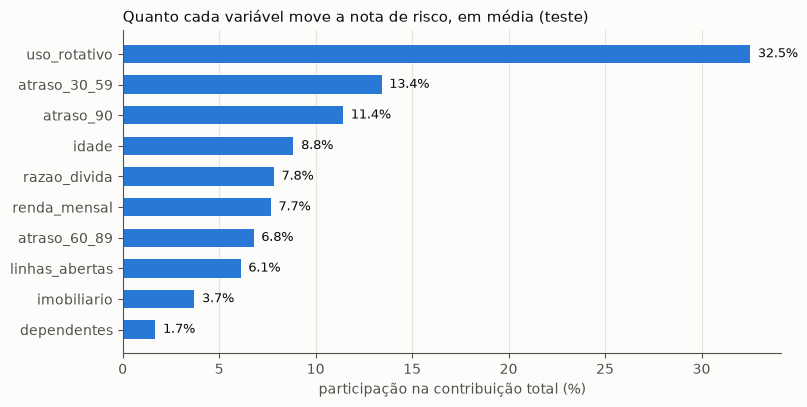

In [3]:
importancia = shap.abs().mean().sort_values(ascending=False)
participacao = importancia / importancia.sum() * 100
global_ = pd.DataFrame(
    {"contribuição média absoluta (log-odds)": importancia, "% do total": participacao}
)
display(global_)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
y_pos = np.arange(len(importancia))[::-1]
ax.barh(y_pos, participacao.values, color=AZUL, height=0.6)
for yi, valor in zip(y_pos, participacao.values, strict=True):
    ax.text(valor + 0.4, yi, f"{valor:.1f}%", va="center", fontsize=9, color=TINTA)
ax.set_yticks(y_pos, importancia.index)
ax.set_xlabel("participação na contribuição total (%)")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_title("Quanto cada variável move a nota de risco, em média (teste)", loc="left")
plt.show()

**O uso do rotativo responde por 33% de tudo o que move as notas** — mais que o dobro da
segunda variável. Depois vêm os atrasos de 30-59 dias (13,4%) e de 90 dias ou mais (11,4%).
É a mesma hierarquia que a análise exploratória encontrou com o Information Value, por um
caminho independente: o modelo apoia as decisões no comportamento de crédito.

Duas diferenças em relação à EDA:

- **A idade é a quarta variável mais usada (8,8%)**, à frente de razão de dívida e renda. Na
  EDA, ela tinha poder médio (IV 0,19). O modelo a usa mais do que a relação dela com o alvo,
  sozinha, sugeriria.
- **Os atrasos de 60-89 dias pesam menos (6,8%)** do que o IV deles indicava (0,55). As três
  colunas de atraso carregam informação parecida; o modelo usa mais duas delas e menos a
  terceira.

## 3. Como cada variável age

Cada ponto é um pedido do teste: no eixo horizontal, o valor da variável; no vertical, quanto
ela empurrou a nota daquele pedido. Acima de zero, aumentou o risco; abaixo, reduziu.

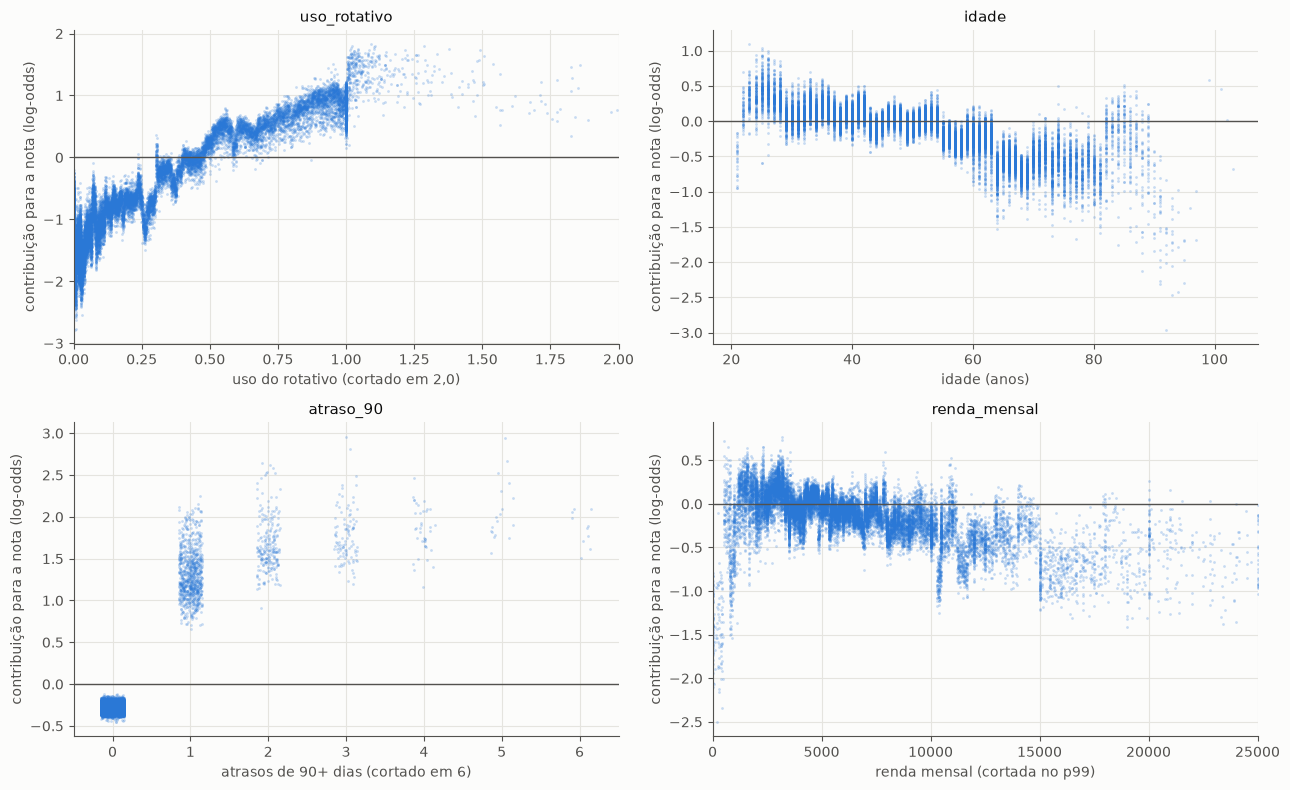

age,50,51,52,53,54,55,56,57,58,59,...,61,62,63,64,65,66,67,68,69,70
contribuição média da idade,-0.0392,0.0100,0.0470,0.0369,0.0205,-0.2092,-0.2058,-0.3040,-0.2952,-0.1791,...,-0.2649,-0.2400,-0.2541,-0.7130,-0.5263,-0.5657,-0.5529,-0.7321,-0.7604,-0.5082


In [4]:
PAINEIS = [
    ("RevolvingUtilizationOfUnsecuredLines", "uso do rotativo (cortado em 2,0)", (0, 2)),
    ("age", "idade (anos)", None),
    ("NumberOfTimes90DaysLate", "atrasos de 90+ dias (cortado em 6)", (-0.5, 6.5)),
    (
        "MonthlyIncome",
        "renda mensal (cortada no p99)",
        (0, float(teste["MonthlyIncome"].quantile(0.99))),
    ),
]
fig, eixos = plt.subplots(2, 2, figsize=(13, 8))
for ax, (coluna, rotulo, limite) in zip(eixos.flat, PAINEIS, strict=True):
    valores = teste[coluna].to_numpy(dtype=float)
    if coluna == "NumberOfTimes90DaysLate":
        valores = valores + np.random.default_rng(0).uniform(-0.15, 0.15, len(valores))
    ax.scatter(valores, shap[NOMES[coluna]], s=4, alpha=0.25, color=AZUL, linewidths=0)
    ax.axhline(0, color=TINTA_2, linewidth=1)
    if limite:
        ax.set_xlim(*limite)
    ax.set(xlabel=rotulo, ylabel="contribuição para a nota (log-odds)", title=NOMES[coluna])
fig.tight_layout()
plt.show()

idade_por_ano = shap.groupby(teste["age"].clip(upper=90))["idade"].mean()
transicao = idade_por_ano.loc[50:70]
display(transicao.to_frame("contribuição média da idade").T)

- **Uso do rotativo:** o risco sobe de forma contínua com o uso e dá um salto em 100% — quem
  estourou o limite. Acima de 125%, a contribuição para de subir e começa a cair: o mesmo
  padrão de "valores extremos que se comportam como erro" que a EDA encontrou (seção 6.1).
- **Atrasos de 90+ dias:** nenhum atraso reduz o risco; o primeiro atraso empurra muito para
  cima, e os seguintes acrescentam pouco. O que importa é ter atrasado, mais que quantas vezes.
- **Idade:** contribui para **aumentar** o risco dos 22 aos 30 anos, fica perto de zero até
  os 54 e passa a **reduzir** o risco a partir dos 55. Há dois degraus nítidos: aos 55 (de
  +0,02 para −0,21 em média) e aos 64 (de −0,25 para −0,71). O modelo não trata a idade como
  uma rampa suave, e sim como faixas com saltos — os degraus que a auditoria de equidade
  enxergou como "a idade pesa muito acima dos 60".
- **Renda:** acima de cerca de 3.000, quanto maior a renda, menor o risco, como esperado. Mas
  **rendas muito baixas, abaixo de cerca de 1.000, reduzem fortemente o risco** — o contrário
  do esperado. É o mesmo grupo que a EDA destacou (seção 6.2): renda zero ou quase zero com
  inadimplência abaixo da média e razão de dívida que não pode ser uma razão de verdade. O
  modelo aprendeu um defeito de registro como se fosse sinal de baixo risco.

## 4. Explicações individuais

Três pedidos do teste, escolhidos por critério e não à mão:

- **uma recusa típica** — o pedido recusado com a nota mediana entre os recusados;
- **um caso no limite** — o pedido recusado mais próximo do corte de 0,5;
- **um jovem bom pagador recusado** — entre os pedidos de 18-25 anos que pagaram em dia e
  foram recusados (o grupo que `04_equidade.ipynb` aponta como o mais prejudicado), o de nota
  mediana.

Para cada um, a explicação no formato que um cliente ou um revisor leria: os principais
fatores, em linguagem comum, e o sentido de cada um.

=== Recusa típica ===
RECUSADO | probabilidade estimada (corrigida): 14.7% | desfecho real: pagou em dia
o que mais pesou contra (aumentou o risco):
  - usa 96% do limite do crédito rotativo
  - 16 linha(s) de crédito e empréstimo(s) abertos
  - tem 37 anos
o que mais pesou a favor (reduziu o risco):
  - 0 atraso(s) de 30 a 59 dias em 2 anos
  - 0 atraso(s) de 90 dias ou mais


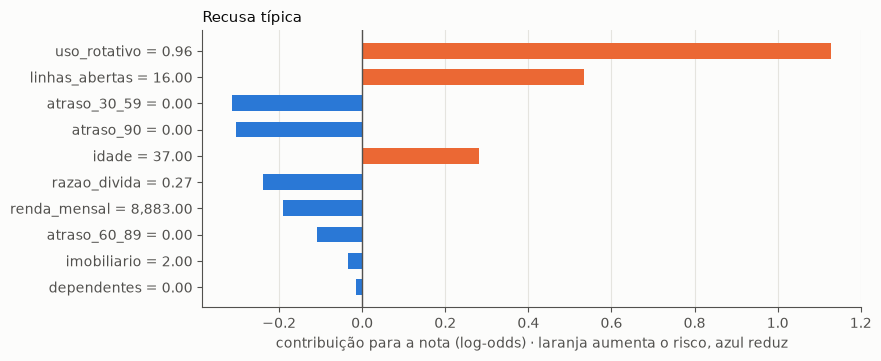

=== Caso no limite ===
RECUSADO | probabilidade estimada (corrigida): 6.9% | desfecho real: pagou em dia
o que mais pesou contra (aumentou o risco):
  - usa 98% do limite do crédito rotativo
  - tem 49 anos
  - compromete 23% da renda com dívidas e custo de vida
o que mais pesou a favor (reduziu o risco):
  - 0 atraso(s) de 30 a 59 dias em 2 anos
  - 0 atraso(s) de 90 dias ou mais


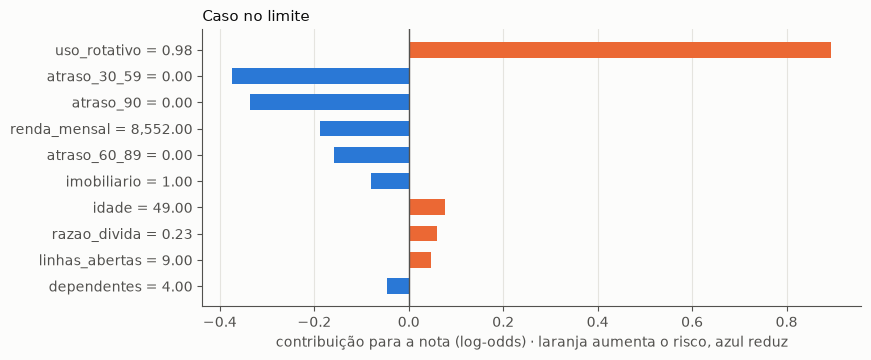

=== Jovem bom pagador recusado ===
RECUSADO | probabilidade estimada (corrigida): 12.8% | desfecho real: pagou em dia
o que mais pesou contra (aumentou o risco):
  - usa 100% do limite do crédito rotativo
  - tem 24 anos
  - renda mensal declarada de 2.500
o que mais pesou a favor (reduziu o risco):
  - 0 atraso(s) de 30 a 59 dias em 2 anos
  - 0 atraso(s) de 90 dias ou mais


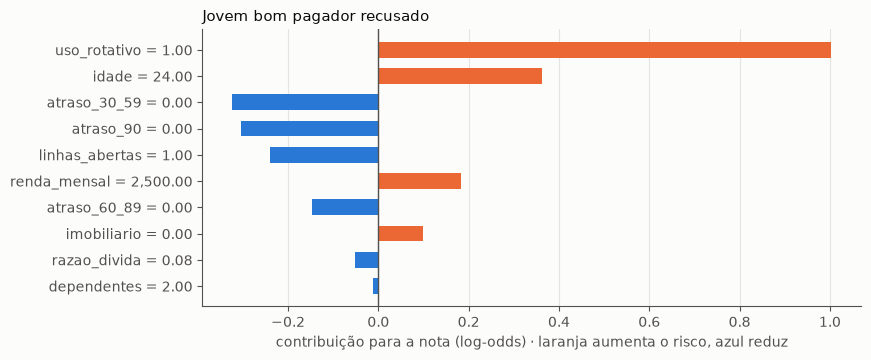

In [5]:
def descrever(coluna: str, valor: float) -> str:
    v = float(valor)
    textos = {
        "RevolvingUtilizationOfUnsecuredLines": f"usa {v:.0%} do limite do crédito rotativo",
        "age": f"tem {v:.0f} anos",
        "NumberOfTime30-59DaysPastDueNotWorse": f"{v:.0f} atraso(s) de 30 a 59 dias em 2 anos",
        "NumberOfTime60-89DaysPastDueNotWorse": f"{v:.0f} atraso(s) de 60 a 89 dias em 2 anos",
        "NumberOfTimes90DaysLate": f"{v:.0f} atraso(s) de 90 dias ou mais",
        "DebtRatio": f"compromete {v:.0%} da renda com dívidas e custo de vida",
        "MonthlyIncome": f"renda mensal declarada de {v:,.0f}".replace(",", "."),
        "NumberOfOpenCreditLinesAndLoans": f"{v:.0f} linha(s) de crédito e empréstimo(s) abertos",
        "NumberRealEstateLoansOrLines": f"{v:.0f} financiamento(s) imobiliário(s)",
        "NumberOfDependents": f"{v:.0f} dependente(s)",
    }
    return textos[coluna]


def explicar(posicao: int, titulo: str) -> None:
    linha = teste.iloc[posicao]
    contrib = shap.iloc[posicao]
    ordem = contrib.reindex(contrib.abs().sort_values(ascending=False).index)
    decisao = "RECUSADO" if recusa[posicao] else "APROVADO"
    desfecho = "inadimpliu" if y[posicao] == 1 else "pagou em dia"
    print(f"=== {titulo} ===")
    chance = p_corrigida[posicao]
    print(
        f"{decisao} | probabilidade estimada (corrigida): {chance:.1%} | desfecho real: {desfecho}"
    )
    colunas = {NOMES[c]: c for c in X}
    contra = contrib[contrib > 0].sort_values(ascending=False).head(3)
    favor = contrib[contrib < 0].sort_values().head(2)
    print("o que mais pesou contra (aumentou o risco):")
    for nome in contra.index:
        print(f"  - {descrever(colunas[nome], linha[colunas[nome]])}")
    print("o que mais pesou a favor (reduziu o risco):")
    for nome in favor.index:
        print(f"  - {descrever(colunas[nome], linha[colunas[nome]])}")

    fig, ax = plt.subplots(figsize=(8.5, 3.6))
    y_pos = np.arange(len(ordem))[::-1]
    cores = [LARANJA if v > 0 else AZUL for v in ordem.values]
    ax.barh(y_pos, ordem.values, color=cores, height=0.6)
    ax.axvline(0, color=TINTA_2, linewidth=1)
    ax.set_yticks(y_pos, [f"{n} = {linha[colunas[n]]:,.2f}" for n in ordem.index])
    ax.set_xlabel("contribuição para a nota (log-odds) · laranja aumenta o risco, azul reduz")
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_title(titulo, loc="left")
    plt.show()


def mediana_de(mascara: np.ndarray) -> int:
    candidatos = np.flatnonzero(mascara)
    return int(candidatos[np.argsort(p[candidatos])[len(candidatos) // 2]])


tipica = mediana_de(recusa)
limite = int(np.flatnonzero(recusa)[np.argmin(p[recusa])])
jovem_bom_recusado = mediana_de(recusa & (y == 0) & (faixa == "18-25"))

explicar(tipica, "Recusa típica")
explicar(limite, "Caso no limite")
explicar(jovem_bom_recusado, "Jovem bom pagador recusado")

Lidas como um cliente ou um revisor as leria:

- **Recusa típica** (risco estimado de 14,7%, o dobro da média): pesaram contra o uso de 96%
  do rotativo, 16 linhas de crédito abertas e a idade de 37 anos; pesou a favor não ter
  nenhum atraso. A pessoa pagou em dia.
- **Caso no limite** (6,9%, exatamente a média): recusado pelo uso de 98% do rotativo; a idade
  de 49 anos e o comprometimento de 23% da renda pesaram pouco, e não ter atrasos pesou a
  favor. Pagou em dia.
- **Jovem bom pagador recusado** (12,8%): pesaram contra o rotativo no limite (100%), **ter
  24 anos** e a renda de 2.500 — a idade é o segundo motivo da recusa, com contribuição de
  cerca do dobro da renda. Pesou a favor não ter atrasos. Pagou em dia.

As três explicações são concretas e verificáveis — cada fator é um dado que a pessoa
informou. É exatamente o que falta hoje ao registro de decisão: ele guarda as entradas e o
modelo, mas não diz o que pesou. O terceiro caso, porém, mostra o problema da seção 5.

## 5. A idade como motivo de recusa

Uma explicação que diga a alguém "um dos principais motivos da sua recusa é a sua idade" é
difícil de sustentar diante do princípio de não discriminação. Com que frequência isso
aconteceria? Para cada faixa: entre os recusados, em quantos a idade está entre os **três
fatores que mais aumentaram o risco**, e em quantos ela é o **primeiro**.

In [6]:
positivas = shap.clip(lower=0)
posicao_idade = positivas.rank(axis=1, ascending=False, method="first")["idade"]
idade_aumentou = shap["idade"] > 0
entre_tres = (idade_aumentou & (posicao_idade <= 3)).to_numpy()
primeira = (idade_aumentou & (posicao_idade == 1)).to_numpy()

linhas = {}
for nome in FAIXAS_ETARIAS:
    m = recusa & (faixa == nome)
    m_bom = m & (y == 0)
    linhas[nome] = {
        "recusados": int(m.sum()),
        "idade entre os 3 primeiros motivos": float(entre_tres[m].mean()),
        "idade como 1º motivo": float(primeira[m].mean()),
        "idem, só bons pagadores recusados": float(entre_tres[m_bom].mean()),
        "contribuição média da idade": float(shap["idade"][faixa == nome].mean()),
    }
motivo_idade = pd.DataFrame(linhas).T
display(motivo_idade)

,recusados,idade entre os 3 primeiros motivos,idade como 1º motivo,"idem, só bons pagadores recusados",contribuição média da idade
18-25,170.0000,0.8000,0.0765,0.8467,0.3032
26-40,"1,723.0000",0.4980,0.0128,0.5533,0.1351
41-60,"2,444.0000",0.2631,0.0008,0.2953,-0.0483
61+,480.0000,0.0229,0.0021,0.0292,-0.5093


| Faixa | Recusados | Idade entre os 3 principais motivos | Idade como 1º motivo | Entre bons pagadores recusados |
|---|---:|---:|---:|---:|
| 18-25 | 170 | **80%** | 8% | **85%** |
| 26-40 | 1.723 | 50% | 1% | 55% |
| 41-60 | 2.444 | 26% | 0% | 30% |
| 61+ | 480 | 2% | 0% | 3% |

**Para a grande maioria dos jovens recusados, a idade é um dos três principais motivos da
recusa** — 80% dos recusados de 18-25, e 85% entre os que pagariam em dia. Ela raramente é o
primeiro motivo (8%): o uso do crédito vem antes. Mas está quase sempre na explicação.

Para os 61+, acontece o contrário: a idade contribui em média para **reduzir** o risco
(−0,51 em log-odds, contra +0,30 para os 18-25).

Isso transforma o achado da auditoria de equidade numa questão prática. Se o projeto passar a
dar explicações individuais — o que o direito de revisão pede —, **a maioria das explicações
dadas a jovens recusados vai citar a idade como motivo.**

## 6. Conclusões

1. **A explicação individual é possível e exata.** Os valores SHAP do próprio XGBoost dividem
   cada nota entre as variáveis sem erro, e valem também para a probabilidade corrigida. Cada
   decisão pode ser explicada com os fatores que pesaram contra e a favor, em linguagem comum.
2. **O corte do modelo tem uma tradução simples:** recusar quem tem risco estimado acima da
   média da base (6,94%).
3. **O modelo decide com base no comportamento de crédito:** uso do rotativo (33%) e atrasos
   (32% somados) dominam, como a análise exploratória antecipava.
4. **Dois comportamentos do modelo merecem atenção:**
   - **a idade** é a quarta variável mais usada e age em degraus, aos 55 e aos 64 anos;
   - **a renda muito baixa reduz o risco**, um defeito de registro aprendido como sinal.
5. **A idade aparece entre os três principais motivos de 80% das recusas de jovens de 18-25.**
   Uma explicação individual dada a um jovem recusado, na maioria dos casos, citaria a idade —
   difícil de sustentar diante do princípio de não discriminação. A alternativa registrada em
   `04_equidade.ipynb` (treinar com a idade e neutralizá-la na decisão) eliminaria esse motivo
   das explicações, porque a idade deixaria de contribuir para a nota.

**Limites:** um modelo, uma partição; o SHAP explica o que **o modelo** faz, não o que causa a
inadimplência de uma pessoa — essa pergunta é a da análise causal (`02_analise_causal.ipynb`).
As explicações estão em log-odds e em ordem; a tradução de cada contribuição em "pontos
percentuais de chance" não é aditiva e não é feita aqui.